# <span style=color:blue>**Part 1:** Imports</span>

In [1]:
#DS Packages:
import pandas as pd
import numpy as np

#Visualizations:
import plotly.express as px
import matplotlib.pyplot as plt

#Testing:


In [2]:
#Dataset:
game_df = pd.read_csv("data/PS4_GamesSales.csv", encoding='latin1')

# <span style=color:blue>**Part 2:** Inspecting the Dataset</span>

In [3]:
#Checking for the number of rows, entries
game_df.shape

(1034, 9)

In [4]:
#Inspecting the first 10 rows:
game_df.head(10)

,Game,Year,Genre,Publisher,North America,Europe,Japan,Rest of World,Global
0,Grand Theft Auto V,2014.0,Action,Rockstar Games,6.06,9.71,0.60,3.02,19.39
1,Call of Duty: Black Ops 3,2015.0,Shooter,Activision,6.18,6.05,0.41,2.44,15.09
2,Red Dead Redemption 2,2018.0,Action-Adventure,Rockstar Games,5.26,6.21,0.21,2.26,13.94
3,Call of Duty: WWII,2017.0,Shooter,Activision,4.67,6.21,0.40,2.12,13.40
4,FIFA 18,2017.0,Sports,EA Sports,1.27,8.64,0.15,1.73,11.80
5,FIFA 17,2016.0,Sports,Electronic Arts,1.26,7.95,0.12,1.61,10.94
6,Uncharted (PS4),2016.0,Action,Sony Interactive Entertainment,4.49,3.93,0.21,1.70,10.33
7,Spider-Man (PS4),2018.0,Action-Adventure,Sony Interactive Entertainment,3.64,3.39,0.32,1.41,8.76
8,Call of Duty: Infinite Warfare,2016.0,Shooter,Activision,3.11,3.83,0.19,1.36,8.48
9,Fallout 4,2015.0,Role-Playing,Bethesda Softworks,2.91,3.97,0.27,1.34,8.48


In [5]:
#Checking for NULLs:
game_df.isna().sum()

Game               0
Year             209
Genre              0
Publisher        209
North America      0
Europe             0
Japan              0
Rest of World      0
Global             0
dtype: int64

#### Because 1/5 of the Year/Publishers are NULL, we'll need to deal with these values somehow. 

In [6]:
#Observing an overall summary of the dataset:
game_df.describe()

,Year,North America,Europe,Japan,Rest of World,Global
count,825.000000,1034.000000,1034.000000,1034.000000,1034.000000,1034.000000
mean,2015.966061,0.204613,0.248714,0.033636,0.089014,0.576054
std,1.298360,0.563471,0.785491,0.108344,0.249410,1.583534
min,2013.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2015.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2016.000000,0.020000,0.000000,0.000000,0.010000,0.060000
75%,2017.000000,0.120000,0.130000,0.030000,0.050000,0.357500
max,2020.000000,6.180000,9.710000,2.170000,3.020000,19.390000


#### Strangely, over ~1/2 of our dataset is has little to no sales information. This is another note we'll need to keep in mind. 

In [7]:
game_df.dtypes

Game              object
Year             float64
Genre             object
Publisher         object
North America    float64
Europe           float64
Japan            float64
Rest of World    float64
Global           float64
dtype: object

#### We'll need to change the Year's datatype from float64 to datetime.

### Notes: 
1) Deal with NULL year and Publisher values, and decide whether or not to drop them.
2) Investigate why 1/2 of our dataset records little to no sales.
3) Change the datatype for year from float64 to datetime.

### <span style=color:teal>Dealing with the NULL values:</span>

In [8]:
#Looking at Entries with NULL values:
game_df[game_df['Year'].isna()].sort_values('Global', ascending = False)

,Game,Year,Genre,Publisher,North America,Europe,Japan,Rest of World,Global
447,Ultra Street Fighter IV,NaN,Fighting,NaN,0.0,0.08,0.00,0.01,0.10
466,Dragon's Dogma Online,NaN,Role-Playing,NaN,0.0,0.00,0.09,0.00,0.09
630,This War of Mine,NaN,Action,NaN,0.0,0.02,0.00,0.00,0.03
724,A Boy and His Blob,NaN,Platform,NaN,0.0,0.00,0.00,0.00,0.00
727,Another World,NaN,Adventure,NaN,0.0,0.00,0.00,0.00,0.00
...,...,...,...,...,...,...,...,...,...
1019,Sakuna: Of Rice and Ruin,NaN,Action,NaN,0.0,0.00,0.00,0.00,0.00
1029,Fallen Legion: Flames of Rebellion,NaN,Role-Playing,NaN,0.0,0.00,0.00,0.00,0.00
1031,The Mummy Demastered,NaN,Action,NaN,0.0,0.00,0.00,0.00,0.00
1032,Project Nimbus: Code Mirai,NaN,Action,NaN,0.0,0.00,0.00,0.00,0.00


#### Given most of the NULL entries have <= 0.10 Global Sales, it's safe to assume most of the entries with low sales numbers did not list the release year nor Publisher. We will make 2 datasets: one with the NULL values, and one without. 

In [9]:
#[NEW DATASET] Dropping NAs:
f_game_df = game_df.dropna()



#Appending "Unknown" to Entries with NULLs: 
game_df['Publisher'] = game_df['Publisher'].replace('Unknown', np.nan)

### <span style=color:teal>Looking into Filtered Dataset's Sales Data:</span>

In [10]:
f_game_df.describe()

,Year,North America,Europe,Japan,Rest of World,Global
count,825.000000,825.000000,825.000000,825.000000,825.000000,825.000000
mean,2015.966061,0.256448,0.311600,0.042048,0.111552,0.721721
std,1.298360,0.620259,0.868271,0.119814,0.274713,1.743122
min,2013.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2015.000000,0.000000,0.000000,0.000000,0.000000,0.030000
50%,2016.000000,0.050000,0.020000,0.000000,0.020000,0.120000
75%,2017.000000,0.190000,0.220000,0.040000,0.090000,0.560000
max,2020.000000,6.180000,9.710000,2.170000,3.020000,19.390000


### <span style=color:teal> Visualizing at Sales Data: </span>

Text(0.5, 0, 'Games')

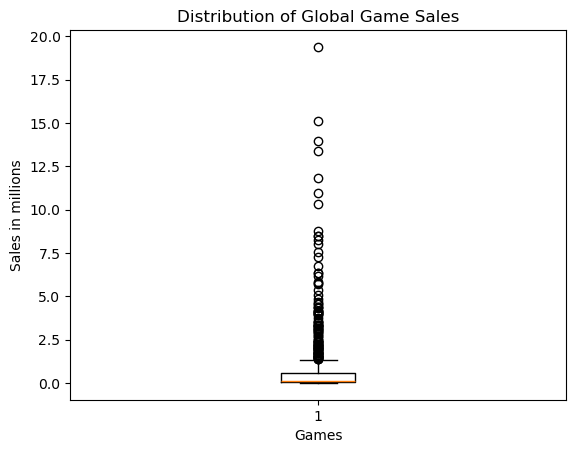

In [11]:
#Creating the Boxplot for Global Sales Data:
plt.boxplot(f_game_df['Global'])

#Establing the title for the plot:
plt.title('Distribution of Global Game Sales')

#Writing a x/y-axis label: 
plt.ylabel('Sales in millions')
plt.xlabel('Games')


Text(0, 0.5, 'Frequency')

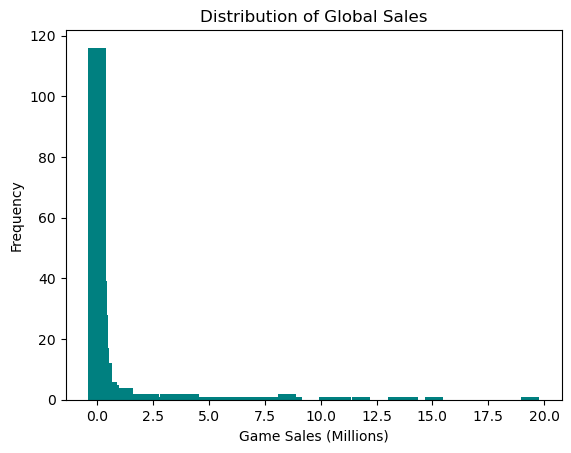

In [12]:
#Creating the Barplot for Global Sales Data:

#Value Counts:
sales_counts = f_game_df['Global'].value_counts()

#Generating Visualization:
plt.bar(sales_counts.index, sales_counts.values, color = 'teal')

#Titles/labels:
plt.title('Distribution of Global Sales')
plt.xlabel('Game Sales (Millions)')
plt.ylabel('Frequency')

#### Using this visualization, we can now see that our distribution is incredibly right skewed.

#### **Why this makes sense:** There are a few reasons we have so many outliers.
1) Users: Most people play 1-5 video games for their consoles and not much more.
2) Marketting: The best selling games are often the ones with the most hype/talk around them.
3) Price: Video games are expensive, therefore people are often selective with what they buy. 

#### Given this information, we will not perform standardized testing and rather use non-parametric methods. We'll also need to consider log transformation and other methods if we want to perform other ML methods.

### <span style=color:teal>Converting Year to Datetime</span>

In [13]:
#Making a copy to prevent 
f_game_df = f_game_df.copy()

#Convert Year to type int -> string: 
f_game_df['Year'] = f_game_df['Year'].astype('int') # 2014.0 -> 2014
f_game_df['Year'] = f_game_df['Year'].astype('str') #Turns into string. 

#Changing the data type to PeriodIndex 
f_game_df['Year'] = pd.PeriodIndex(f_game_df['Year'], freq = 'Y') #2014 = 2014-01-01 -> 2014-12-31 in DateTime.

### <span style=color:teal> Final Dataset: </span>

#### <span style="color: #0096FF"> First 5 Rows </span>

In [15]:
f_game_df.head()

,Game,Year,Genre,Publisher,North America,Europe,Japan,Rest of World,Global
0,Grand Theft Auto V,2014,Action,Rockstar Games,6.06,9.71,0.60,3.02,19.39
1,Call of Duty: Black Ops 3,2015,Shooter,Activision,6.18,6.05,0.41,2.44,15.09
2,Red Dead Redemption 2,2018,Action-Adventure,Rockstar Games,5.26,6.21,0.21,2.26,13.94
3,Call of Duty: WWII,2017,Shooter,Activision,4.67,6.21,0.40,2.12,13.40
4,FIFA 18,2017,Sports,EA Sports,1.27,8.64,0.15,1.73,11.80


#### <span style="color: #0096FF"> Data Types </span>

In [17]:
f_game_df.dtypes

Game                    object
Year             period[Y-DEC]
Genre                   object
Publisher               object
North America          float64
Europe                 float64
Japan                  float64
Rest of World          float64
Global                 float64
dtype: object

#### <span style="color: #0096FF"> Summary Stats/Quartiles </span>

In [20]:
f_game_df.describe()

,North America,Europe,Japan,Rest of World,Global
count,825.000000,825.000000,825.000000,825.000000,825.000000
mean,0.256448,0.311600,0.042048,0.111552,0.721721
std,0.620259,0.868271,0.119814,0.274713,1.743122
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.030000
50%,0.050000,0.020000,0.000000,0.020000,0.120000
75%,0.190000,0.220000,0.040000,0.090000,0.560000
max,6.180000,9.710000,2.170000,3.020000,19.390000


#### <span style="color: #0096FF"> Null Value Counts: </span>

In [22]:
f_game_df.isna().sum()

Game             0
Year             0
Genre            0
Publisher        0
North America    0
Europe           0
Japan            0
Rest of World    0
Global           0
dtype: int64

# <span style=color:blue>**Part 4:** Exporting the Dataset</span>

In [25]:
#Exporting as a CSV, not recording Pandas indices: 
f_game_df.to_csv('Updated_PS4_Game_Sales.csv',index = False)